# Iris Flower Classification
**Author:** Syed Aon Muhammad Kazmi  
**Track:** Data Science | OASIS INFOBYTE

## Objective and data
Data: built-in scikit-learn Iris dataset, https://scikit-learn.org/stable/auto_examples/datasets/plot_iris_dataset.html. Measurements are in cm; this small benchmark does not establish real-world performance.

Reproducible seed: 42. Model selection uses cross-validation on training data; the held-out test set is evaluated once per candidate for reporting.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, KFold
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, classification_report, ConfusionMatrixDisplay,
                             mean_absolute_error, mean_squared_error, r2_score)
sns.set_theme(style='whitegrid', palette='colorblind')
SEED = 42
OUT = Path('outputs'); OUT.mkdir(exist_ok=True)
def save(name):
    plt.savefig(OUT / f'{name}.png', dpi=160, bbox_inches='tight')
    plt.show()
def inspect(df):
    print('Shape:', df.shape)
    display(df.head(), df.dtypes.to_frame('dtype'), df.isna().sum().to_frame('missing'), df.describe(include='all'))


In [2]:
from sklearn.datasets import load_iris
iris = load_iris(as_frame=True)
df = iris.frame.copy()
df['species'] = df.target.map(dict(enumerate(iris.target_names)))
inspect(df)

Shape: (150, 6)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


,dtype
sepal length (cm),float64
sepal width (cm),float64
petal length (cm),float64
petal width (cm),float64
target,int64
species,object


,missing
sepal length (cm),0
sepal width (cm),0
petal length (cm),0
petal width (cm),0
target,0
species,0


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
count,150.000000,150.000000,150.000000,150.000000,150.000000,150
unique,NaN,NaN,NaN,NaN,NaN,3
top,NaN,NaN,NaN,NaN,NaN,setosa
freq,NaN,NaN,NaN,NaN,NaN,50
mean,5.843333,3.057333,3.758000,1.199333,1.000000,NaN
std,0.828066,0.435866,1.765298,0.762238,0.819232,NaN
min,4.300000,2.000000,1.000000,0.100000,0.000000,NaN
25%,5.100000,2.800000,1.600000,0.300000,0.000000,NaN
50%,5.800000,3.000000,4.350000,1.300000,1.000000,NaN
75%,6.400000,3.300000,5.100000,1.800000,2.000000,NaN


## Feature distributions
Compare species separation in the pairplot and feature ranges in the box plots.

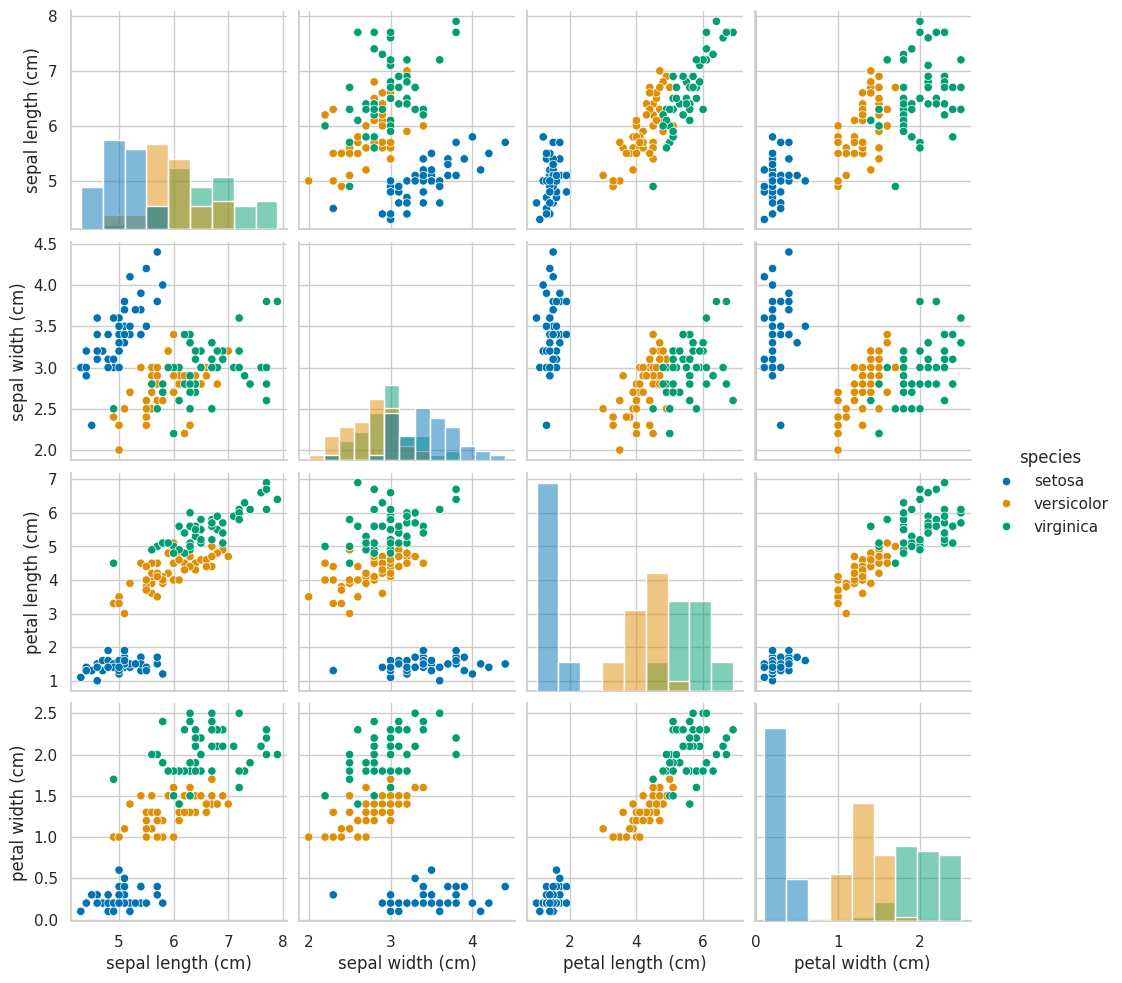

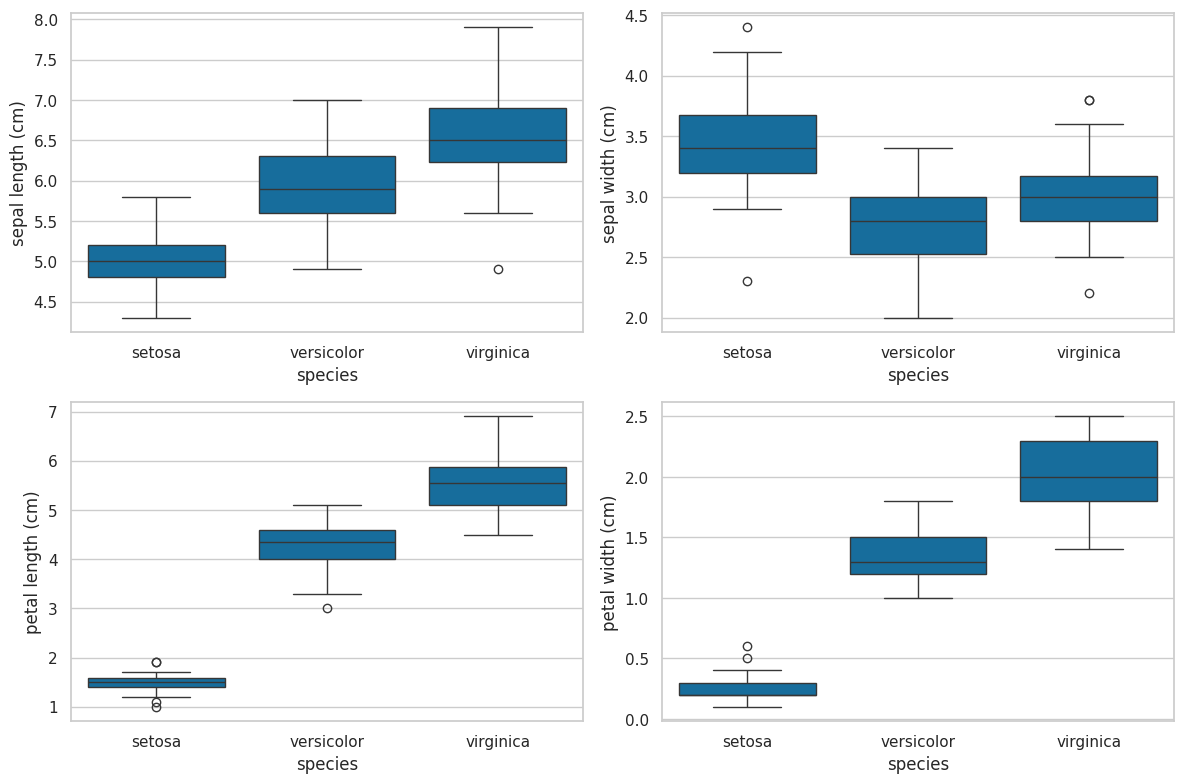

In [3]:
sns.pairplot(df, vars=iris.feature_names, hue='species', diag_kind='hist'); save('pairplot')
fig, axes = plt.subplots(2,2,figsize=(12,8))
for ax, feature in zip(axes.flat,iris.feature_names):
    sns.boxplot(data=df,x='species',y=feature,ax=ax)
plt.tight_layout(); save('feature_boxplots')

Petal length and width visibly separate Setosa and help distinguish the other species. Sepal measurements overlap more. We retain all four features: low dimensionality and training-only validation make this a reasonable baseline without selecting features from test outcomes.

Logistic Regression
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

KNN
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30

Selected model: Logistic Regression based on highest training CV accuracy; ties prefer Logistic Regression for simplicity.
Example prediction: setosa


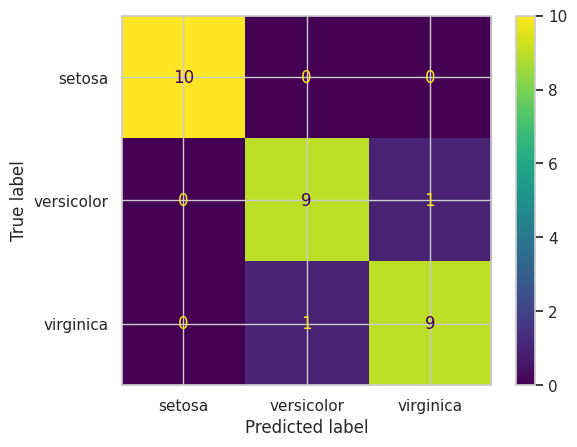

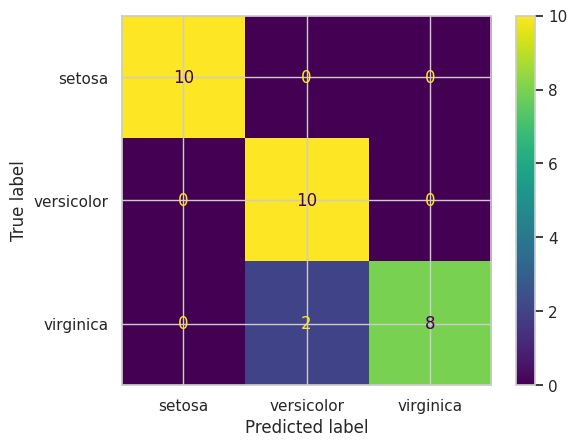

,Model,CV accuracy,CV std,Test accuracy
0,Logistic Regression,0.958333,0.026352,0.933333
1,KNN,0.958333,0.026352,0.933333


In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
X_train,X_test,y_train,y_test=train_test_split(iris.data,iris.target,test_size=.2,stratify=iris.target,random_state=SEED)
models={'Logistic Regression':make_pipeline(StandardScaler(),LogisticRegression(max_iter=1000)), 'KNN':make_pipeline(StandardScaler(),KNeighborsClassifier(n_neighbors=5))}
cv=StratifiedKFold(5,shuffle=True,random_state=SEED)
rows=[]
for name,model in models.items():
    scores=cross_val_score(model,X_train,y_train,cv=cv,scoring='accuracy')
    model.fit(X_train,y_train); pred=model.predict(X_test)
    rows.append({'Model':name,'CV accuracy':scores.mean(),'CV std':scores.std(),'Test accuracy':accuracy_score(y_test,pred)})
    print(name); print(classification_report(y_test,pred,target_names=iris.target_names,zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_test,pred,display_labels=iris.target_names); save(name.replace(' ','_')+'_confusion')
results=pd.DataFrame(rows).sort_values('CV accuracy',ascending=False,kind='stable');display(results)
results.to_csv(OUT/'metrics.csv',index=False)
best_name=results.iloc[0]['Model']; print('Selected model:',best_name,'based on highest training CV accuracy; ties prefer Logistic Regression for simplicity.')
print('Example prediction:',iris.target_names[models[best_name].predict(X_test.iloc[[0]])[0]])

## Limitations
The test set has only 30 flowers, so one mistake changes accuracy by 3.33 percentage points. Cross-validation is more informative than a perfect score on one split. Scaling is fitted within each training fold to prevent leakage.

## Results from the verified run
Both classifiers achieved 95.83% mean training CV accuracy and 93.33% held-out accuracy. Logistic Regression is selected by the stated simplicity tie-break. Neither classifier is demonstrably superior on this split.